# 05 · Curva de calibración: ¿cuántos ensayos del sujeto nuevo hacen falta, y para qué?

**H3:** con 10 a 20 ensayos de calibración se recupera buena parte de la diferencia.

Para cada uno de los 106 sujetos que se deja afuera se toman **k** ensayos de calibración (k = 0, 5, 10, 20, 30, estratificados por clase) y se evalúa con el resto de sus ensayos. Cada k se repite 10 veces con distintos ensayos de calibración. Configuración base del notebook 02 (CSP + LDA, 8–30 Hz, 0,5–2,5 s).

| Estrategia | Qué usa del sujeto nuevo |
|---|---|
| General, sin ajustar | Nada: modelo entrenado con los otros 105 sujetos |
| General + umbral | Los k ensayos, solo para recentrar el umbral de decisión (punto medio entre los puntajes medios de cada clase). No cambia el AUC |
| General alineado + umbral | Modelo entrenado con sujetos alineados (alineación euclídea); el sujeto nuevo se alinea con la covarianza de sus k ensayos y se recentra el umbral |
| Personal | Un CSP + LDA entrenado solo con sus k ensayos (k ≥ 10) |

A diferencia del notebook 04, la alineación del sujeto nuevo usa **solo** sus k ensayos de calibración: es la versión realista.

Los resultados se calculan con `experimentos/etapa5.py` (unos 45 minutos). Este notebook solo los analiza.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
from IPython.display import Image
from scipy.stats import wilcoxon

from bci.pipelines import itr_bits_por_minuto, umbral_azar

RESULTADOS = Path("..") / "resultados"
NOMBRE = {"general": "General, sin ajustar", "general_umbral": "General + umbral",
          "alineado_umbral": "General alineado + umbral", "personal": "Personal"}

df = pd.read_csv(RESULTADOS / "05_calibracion.csv")
# Primero se promedian las 10 repeticiones de cada sujeto, para que todos los sujetos pesen igual.
suj = df.groupby(["sujeto", "k", "estrategia"])[["balanced_accuracy", "auc", "n_prueba"]].mean().reset_index()
suj["sobre_azar"] = suj["balanced_accuracy"] >= suj["n_prueba"].round().astype(int).map(umbral_azar)
suj["itr"] = itr_bits_por_minuto(suj["balanced_accuracy"], 2.5)  # 2,5 s por decisión (final de la ventana)
print(suj.groupby(["k", "estrategia"]).size().unstack())


estrategia  alineado_umbral  general  general_umbral  personal
k                                                             
0                       NaN    106.0             NaN       NaN
5                     106.0    106.0           106.0       NaN
10                    106.0    106.0           106.0     106.0
20                    106.0    106.0           106.0     106.0
30                    106.0    106.0           106.0     106.0


## Tabla resumen

Medias sobre los 106 sujetos. *Sobre el azar*: sujetos cuya balanced accuracy supera el umbral binomial (p < 0,05) para su cantidad de ensayos de prueba.

In [2]:
tabla = suj.groupby(["k", "estrategia"]).agg(
    BA=("balanced_accuracy", "mean"), AUC=("auc", "mean"), ITR=("itr", "mean"), sobre_azar=("sobre_azar", "sum"))
tabla = tabla.rename(index=NOMBRE, level="estrategia")
tabla.to_csv(RESULTADOS / "05_tabla_resumen.csv")
tabla.round(3)


BA    AUC    ITR  sobre_azar
k  estrategia                                                
0  General, sin ajustar       0.623  0.709  2.467          37
5  General alineado + umbral  0.676  0.743  3.585          58
   General, sin ajustar       0.624  0.709  2.451          37
   General + umbral           0.647  0.709  2.804          42
10 General alineado + umbral  0.684  0.745  3.942          57
   General, sin ajustar       0.622  0.707  2.435          36
   General + umbral           0.653  0.707  3.141          42
   Personal                   0.537  0.555  0.499          10
20 General alineado + umbral  0.691  0.749  4.343          41
   General, sin ajustar       0.622  0.710  2.438          29
   General + umbral           0.658  0.710  3.302          31
   Personal                   0.567  0.593  1.357          12
30 General alineado + umbral  0.690  0.746  4.347          26
   General, sin ajustar       0.625  0.709  2.468          15
   General + umbral           0.663  0.709  3.500          22
   Personal                   0.590  0.621  2.084           9

## Pruebas estadísticas

Cada estrategia contra el modelo general sin ajustar **con el mismo k** (mismos ensayos de prueba), Wilcoxon pareado por sujeto. También: ¿sigue mejorando el modelo alineado al agregar ensayos?

In [3]:
ancho = suj.pivot_table(index=["sujeto", "k"], columns="estrategia", values="balanced_accuracy")
filas = []
for k in [5, 10, 20, 30]:
    a = ancho.xs(k, level="k")
    for e in ["general_umbral", "alineado_umbral", "personal"]:
        if a[e].isna().all():
            continue
        filas.append({"k": k, "estrategia": NOMBRE[e], "BA": a[e].mean(), "BA general": a["general"].mean(),
                      "diferencia": (a[e] - a["general"]).mean(), "p Wilcoxon": wilcoxon(a[e], a["general"]).pvalue,
                      "sujetos que mejoran": int((a[e] > a["general"]).sum())})
pruebas = pd.DataFrame(filas)
pruebas.to_csv(RESULTADOS / "05_pruebas.csv", index=False)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pruebas)

alin = ancho["alineado_umbral"].unstack("k")
for k1, k2 in [(5, 10), (10, 20), (20, 30)]:
    print(f"Alineado + umbral, k={k1} -> k={k2}: {alin[k1].mean():.3f} -> {alin[k2].mean():.3f}, "
          f"p = {wilcoxon(alin[k1], alin[k2]).pvalue:.2g}")


,k,estrategia,BA,BA general,diferencia,p Wilcoxon,sujetos que mejoran
0,5,General + umbral,0.647,0.624,0.0228,0.000113,70
1,5,General alineado + umbral,0.676,0.624,0.0523,1.24e-08,78
2,10,General + umbral,0.653,0.622,0.0311,8.78e-08,80
3,10,General alineado + umbral,0.684,0.622,0.0621,2.93e-10,81
4,10,Personal,0.537,0.622,-0.0851,1.93e-12,20
5,20,General + umbral,0.658,0.622,0.0363,5.66e-08,80
6,20,General alineado + umbral,0.691,0.622,0.0692,3.77e-11,83
7,20,Personal,0.567,0.622,-0.0556,2.87e-08,28
8,30,General + umbral,0.663,0.625,0.0378,1.04e-07,77
9,30,General alineado + umbral,0.69,0.625,0.065,4.35e-10,80


Alineado + umbral, k=5 -> k=10: 0.676 -> 0.684, p = 0.0014
Alineado + umbral, k=10 -> k=20: 0.684 -> 0.691, p = 0.0071
Alineado + umbral, k=20 -> k=30: 0.691 -> 0.690, p = 0.61


## Figura · Curva de calibración

La genera `experimentos/figura_etapa5.py` (es la misma que va en el informe). La línea punteada es el modelo personal del notebook 02, entrenado con unos 36 ensayos por validación cruzada.

listo: F:\Users\Lucas\Scripts\tfi-bci-imagineria-motora\resultados\05_calibracion.png


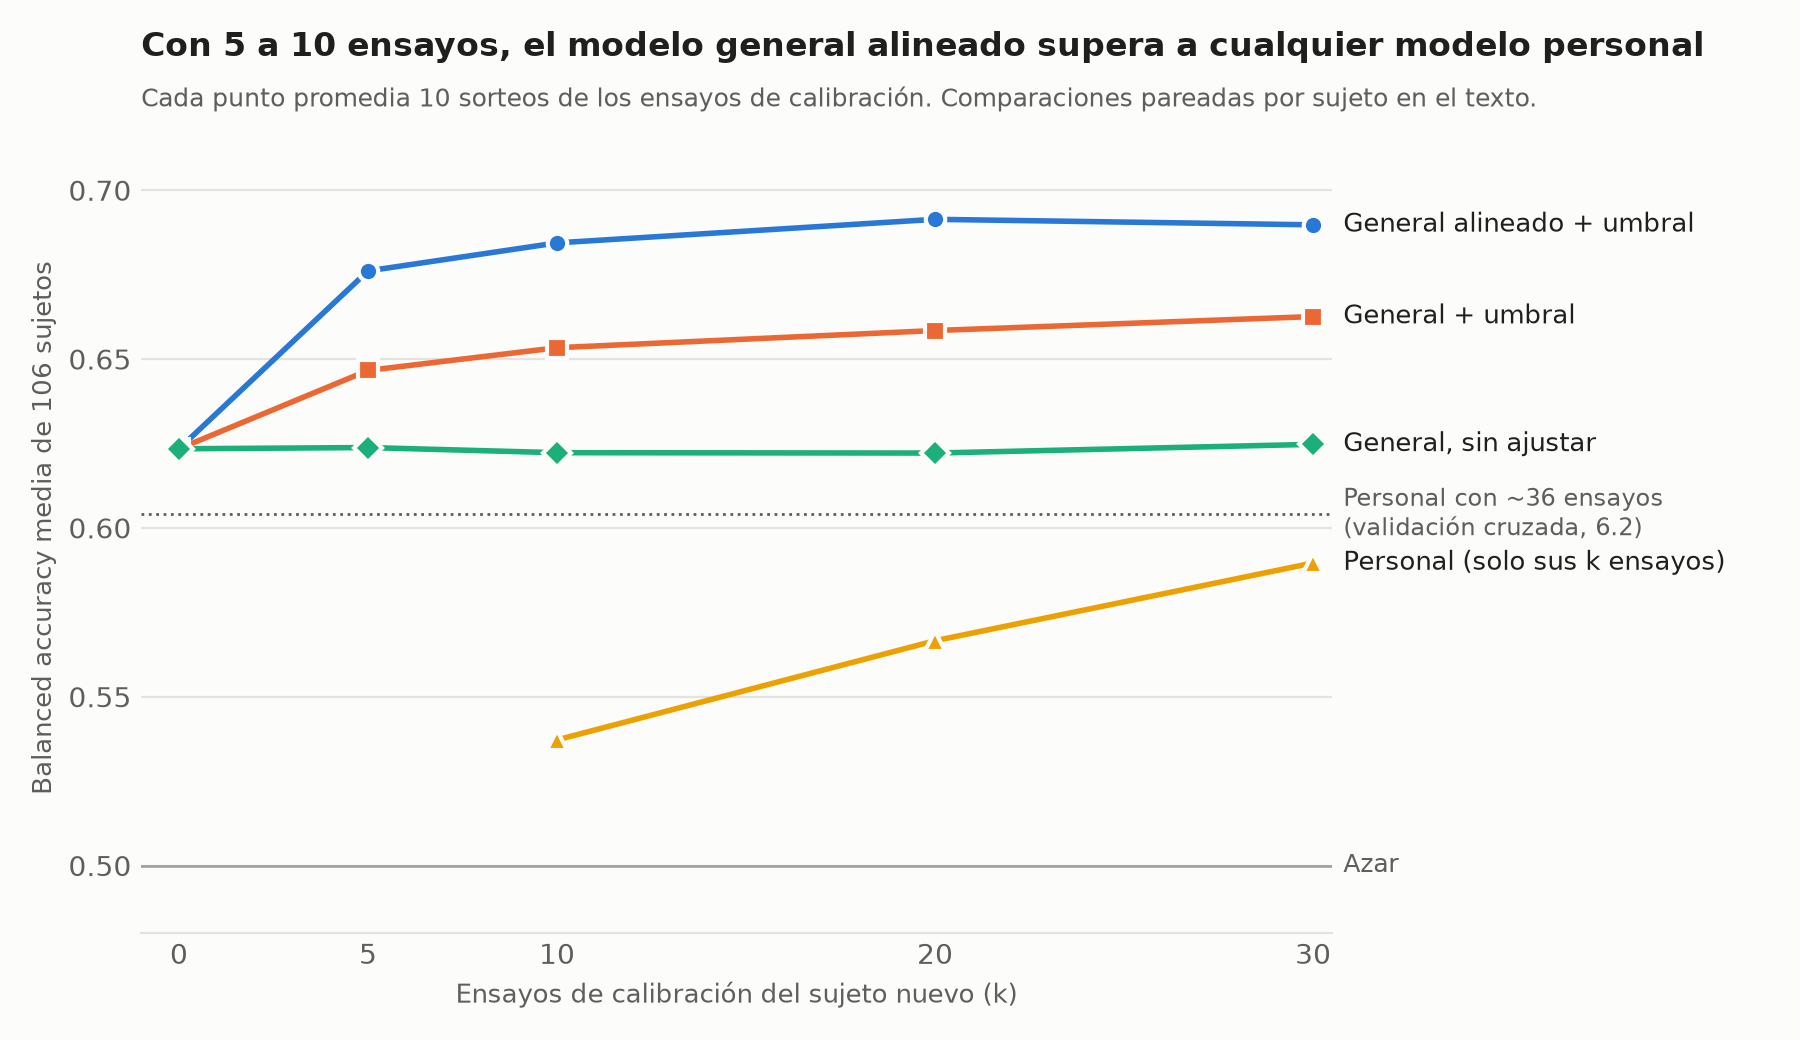

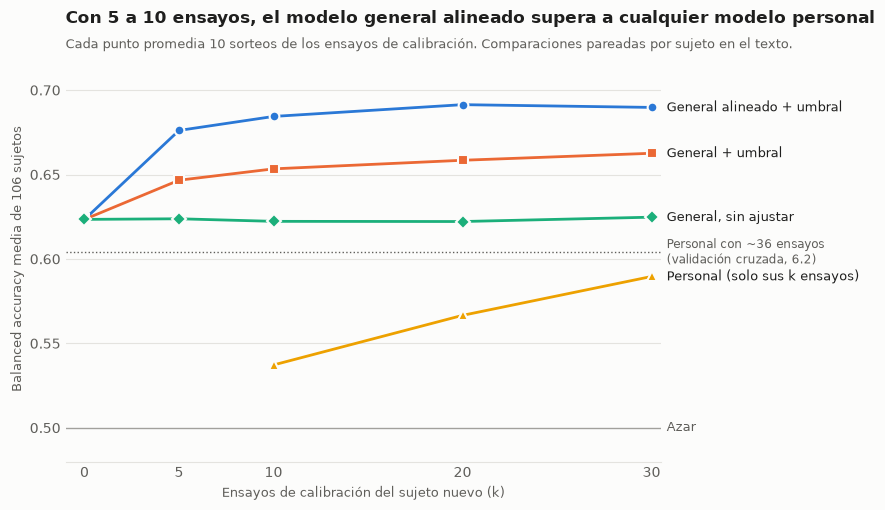

In [4]:
from experimentos.figura_etapa5 import main as figura_calibracion

figura_calibracion()
Image(RESULTADOS / "05_calibracion.png", width=800)


## ¿A quién ayuda la calibración?

Mejora del modelo alineado con 10 ensayos respecto del general sin ajustar, según qué tan bien le iba a cada sujeto con el modelo general.

In [5]:
a10 = ancho.xs(10, level="k")
grupos = pd.qcut(a10["general"], 3, labels=["tercio bajo", "tercio medio", "tercio alto"])
(a10["alineado_umbral"] - a10["general"]).groupby(grupos, observed=True).agg(["mean", "median", "count"]).round(3)


,mean,median,count
general,,,
tercio bajo,0.090,0.102,36
tercio medio,0.068,0.074,35
tercio alto,0.028,0.042,35


## Lectura de los resultados

**1. H3 se sostiene, y con margen.** Con solo 5 ensayos del sujeto nuevo, el modelo general alineado y con umbral recentrado pasa de 0,624 a 0,676 de balanced accuracy (p = 1,2 × 10⁻⁸, mejora en 78 de 106 sujetos). Con 10 ensayos llega a 0,684 y con 20 a 0,691, el mismo valor que la alineación con todos los ensayos del notebook 04. De 20 a 30 ya no mejora (p = 0,61). El ITR pasa de 2,5 a 4,3 bits/min.

**2. Lo que funciona es adaptar, no reentrenar.** Las dos estrategias que usan los k ensayos para *ajustar* el modelo general le ganan al modelo *personal* entrenado con esos mismos ensayos:

- Recentrar solo el umbral ya mejora (0,647 con 5 ensayos, sin cambiar el AUC). Confirma la lectura del notebook 02: el modelo general ordena bien, pero su punto de corte no coincide con el de cada persona.
- Alinear suma bastante más, y además sube el AUC (0,709 → 0,743): no solo corrige el umbral, sino que acerca los datos de la persona a los del entrenamiento.
- El modelo personal con 30 ensayos (0,590) queda por debajo del general sin ajustar (0,625, p = 5 × 10⁻⁴) y del personal del notebook 02 (0,604, entrenado con unos 36 ensayos).

Las dos correcciones necesitan muy pocos datos: la alineación no usa etiquetas, y el umbral solo necesita el puntaje medio de cada clase. El modelo personal, en cambio, tiene que estimar los filtros CSP y el clasificador desde cero.

**3. ¿A quién ayuda?** Con 10 ensayos, la mejora es mayor en los sujetos a los que peor les iba con el modelo general (+0,09 en el tercio inferior, +0,07 en el medio, +0,03 en el superior). Hay que leerlo con cautela: como los tercios se arman con el mismo resultado que se compara, parte de esa diferencia puede ser regresión a la media.

**Cómo leer la columna "sobre el azar".** Disminuye al aumentar k porque quedan menos ensayos de prueba y el umbral binomial sube (con 15 ensayos de prueba hace falta 0,80). Solo es comparable entre estrategias con el mismo k.

**Limitaciones.** Evaluación offline, con los ensayos de calibración sorteados del mismo registro. En una BCI real la calibración sería al comienzo de la sesión y la señal podría cambiar después. Con k grande quedan pocos ensayos de prueba por sujeto, así que cada estimación individual es ruidosa; por eso se promedian 10 sorteos.
